# 9-8. SV 원 스케일 -- 리샘플링 vs 자체 7분위 구간 비교

**전체 계획** (auto_arima 기반 + SV/SV)

1. `9-1`~`9-4`: auto_arima 기반 d 고정, p,q 선택, 원/로그 스케일 구간 비교
2. `9-5`: GARCH·SV 동시최적화 구현과 검증, `9-6`·`9-7`: GARCH 원/로그 스케일
3. **`9-8`: SV 원 스케일** (이 노트북, `9-3` 과정)
4. `9-9`: SV 로그 스케일 (`9-4` 과정)
5. `9-10`: auto_arima vs GARCH vs SV 종합 비교

**모델**: AR(p)+SV(1) **동시최적화**(직접 구현한 QML + 칼만필터, 평균 제거 없음, phi 상한 0.97), d=1 고정. AR 차수 p는 origin마다 AR단독 `auto_arima`(AICc)가 선택한다(`9-5`). 공통 데이터·평가 설정은 `9-1`의 0절을 따른다.

**비교**: 같은 SV 점예측 위에서 구간 생성법만 다르게 한다.
- **자체 구간**: SV가 내는 단계별 σ로 만든 정규분포 구간(`level_sigma`로 수준 σ 전파).
- **리샘플링 구간**: 이 모델의 과거 h단계 표준화 오차를 중심화해 500개 복원추출하고 현재 σ_h를 곱해 점예측에 더한 분포(아래 설명). 두 구간의 중심이 같다.

AR+SV 두 구간 방식(자체·리샘플링)은 같은 모델의 점예측을 쓰므로 점예측과 MSE가 같고, **커버리지와 CRPS(7분위)** 가 비교 대상이다. SV 적합이 실패하면 AR단독 예측으로 대체하고 그 횟수를 보고한다.

**origin 표기**: `origin 35 (훈련 2011Q1~2019Q3, 예측 2019Q4~2020Q3)`처럼 훈련·예측 기간을 함께 적는다.

**리샘플링 방식 -- 필터링된 과거 시뮬레이션(표준화 오차 리샘플링)**: SV는 시점마다 σ_h가 달라지는 모델이다. 과거 오차를 그대로 뽑으면 지금 origin의 σ_h가 구간에 반영되지 않으므로, 오차를 σ_h로 표준화해서 뽑는다.
1. 과거 각 origin에서 h단계 오차를 그때의 모델 σ_h로 나눈 **표준화 오차** `z = (실제 - 예측) / σ_h`를 모은다(그 origin 이전에 확정된 것만).
2. z의 **중앙값을 빼서 중심화**한다(두 구간의 중심을 같게 해 구간 방식만 비교하기 위함).
3. 중심화한 z에서 500개를 복원추출한다.
4. **지금 origin의 σ_h를 곱해** 점예측에 더한다: `점예측 + σ_h x (z - 중앙값(z))`.

분산이 일정한 auto_arima(`9-3`, `9-4`)는 σ_h가 시점에 따라 변하지 않아 표준화가 상수배일 뿐이므로 원 오차를 그대로(중심화만) 쓴다. 이 노트북의 '오차 표본 std ÷ σ'는 표준화 오차 z의 표준편차와 같다(1보다 크면 과거에 모델 σ가 실제 오차보다 작았다).


In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from scipy.optimize import minimize
from scipy import stats

H, MIN_TRAIN, INITIAL_CALIB, ALPHA = 4, 20, 15, 0.10
Z = stats.norm.ppf(1 - ALPHA / 2)
D, N_RESAMPLE, P_MAX, SCALE = 1, 500, 3, 100.0
XI_MEAN, XI_VAR, MAX_PHI = -1.2704, np.pi ** 2 / 2, 0.97

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
data = raw[["quarter", "X3_l1"]].dropna().reset_index(drop=True)
quarters, vals = data["quarter"].values, data["X3_l1"].values.astype(float)
LOG = SCALE * np.log(vals)
var_std = vals.std()
origins = list(range(MIN_TRAIN, len(vals) - H + 1))
scored_origins = origins[INITIAL_CALIB:]
FIRST = scored_origins[0]
LEVELS = np.array([0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9])


def label(o):
    return f"origin {o} (훈련 {quarters[0]}~{quarters[o - 1]}, 예측 {quarters[o]}~{quarters[o + H - 1]})"


def pinball(q, y, tau):
    return np.where(y >= q, (y - q) * tau, (q - y) * (1 - tau))


def crps7(q7, y):
    return 2 * np.mean([pinball(q7[k], y, LEVELS[k]) for k in range(7)]) / var_std


def to_orig(x):
    return np.exp(np.asarray(x) / SCALE)


def difference(values, d):
    x = np.asarray(values, dtype=float)
    hist = []
    for _ in range(d):
        hist.append(x.copy())
        x = np.diff(x)
    return x, hist


def undiff_mean(diff_fc, hist, d):
    fc = np.asarray(diff_fc, dtype=float)
    for i in reversed(range(d)):
        fc = hist[i][-1] + np.cumsum(fc)
    return fc


def level_sigma(ar_coefs, d, innov_var):
    p = len(ar_coefs)
    psi = np.zeros(H)
    for j in range(H):
        psi[j] = 1.0 if j == 0 else sum(ar_coefs[k] * psi[j - 1 - k] for k in range(min(p, j)))
    for _ in range(d):
        psi = np.cumsum(psi)
    return np.sqrt(np.array([sum(psi[h - i] ** 2 * innov_var[i] for i in range(h + 1)) for h in range(H)]))


def select_p(train):
    # AR단독 auto_arima(정확우도, AICc): d=1 고정, MA 없음, 절편 없음 -> SV의 AR 차수로 사용
    m = pm.auto_arima(train, d=D, seasonal=False, start_q=0, max_q=0, max_p=P_MAX, information_criterion="aicc",
                      with_intercept=False, suppress_warnings=True, error_action="ignore")
    return m.order[0], m


def ar_fallback(m):
    fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    return np.asarray(fc), (conf[:, 1] - conf[:, 0]) / (2 * Z)


def is_ar_stable(ar_coefs):
    p = len(ar_coefs)
    if p == 0:
        return True
    companion = np.zeros((p, p))
    companion[0, :] = ar_coefs
    if p > 1:
        companion[1:, :-1] = np.eye(p - 1)
    return np.max(np.abs(np.linalg.eigvals(companion))) < 0.999


def level_sigma(ar_coefs, d, innov_var):
    # ARIMA(p,d,0)의 h단계 수준 예측오차 표준편차 (innov_var[i] = (i+1)단계 오차분산)
    p = len(ar_coefs)
    psi = np.zeros(H)
    for j in range(H):
        psi[j] = 1.0 if j == 0 else sum(ar_coefs[k] * psi[j - 1 - k] for k in range(min(p, j)))
    for _ in range(d):
        psi = np.cumsum(psi)
    return np.sqrt(np.array([sum(psi[h - i] ** 2 * innov_var[i] for i in range(h + 1)) for h in range(H)]))


def sv_qml_negloglik(z_centered, phi, sigma_eta2):
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred, loglik = 0.0, P0, 0.0
    for z in z_centered:
        F = P_pred + XI_VAR
        v = z - h_pred
        loglik += -0.5 * (np.log(2 * np.pi * F) + v ** 2 / F)
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return -loglik


def sv_residuals(y, ar):
    p = len(ar)
    return np.array([y[t] - sum(ar[i] * y[t - 1 - i] for i in range(p)) for t in range(p, len(y))])


def joint_sv_negloglik(params, y, p):
    ar, phi, s2 = params[:p], MAX_PHI * np.tanh(params[p]), np.exp(params[p + 1]) ** 2
    if not is_ar_stable(ar):
        return 1e10
    z = np.log(sv_residuals(y, ar) ** 2 + 1e-8)
    return sv_qml_negloglik(z - z.mean(), phi, s2)


def sv_qml_negloglik(z_centered, phi, sigma_eta2):
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred, loglik = 0.0, P0, 0.0
    for z in z_centered:
        F = P_pred + XI_VAR
        v = z - h_pred
        loglik += -0.5 * (np.log(2 * np.pi * F) + v ** 2 / F)
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return -loglik


def sv_residuals(y, ar):
    p = len(ar)
    return np.array([y[t] - sum(ar[i] * y[t - 1 - i] for i in range(p)) for t in range(p, len(y))])


def joint_sv_negloglik(params, y, p):
    ar, phi, s2 = params[:p], MAX_PHI * np.tanh(params[p]), np.exp(params[p + 1]) ** 2
    if not is_ar_stable(ar):
        return 1e10
    z = np.log(sv_residuals(y, ar) ** 2 + 1e-8)
    return sv_qml_negloglik(z - z.mean(), phi, s2)


def sv_forecast(train, p):
    y, hist = difference(train, D)
    res = minimize(joint_sv_negloglik, [0.0] * p + [1.5, np.log(0.3)], args=(y, p), method="Nelder-Mead", options={"maxiter": 3000})
    if not is_ar_stable(res.x[:p]) or res.fun >= 1e9:
        raise ValueError("SV fit failed")
    ar, phi, s2 = res.x[:p], MAX_PHI * np.tanh(res.x[p]), np.exp(res.x[p + 1]) ** 2
    z = np.log(sv_residuals(y, ar) ** 2 + 1e-8)
    zm = z.mean()
    P, h = s2 / (1 - phi ** 2), 0.0
    for x in z - zm:
        K = P / (P + XI_VAR)
        hf, Pf = h + K * (x - h), P * (1 - K)
        h, P = phi * hf, phi ** 2 * Pf + s2
    past = list(y[-p:]) if p else []
    mean_diff = []
    for _ in range(H):
        pred = sum(ar[i] * past[-1 - i] for i in range(p))
        mean_diff.append(pred)
        past.append(pred)
    v = [np.exp(zm - XI_MEAN + phi ** k * hf + (phi ** (2 * k) * Pf + s2 * sum(phi ** (2 * j) for j in range(k))) / 2) for k in range(1, H + 1)]
    fc, sig = undiff_mean(mean_diff, hist, D), level_sigma(ar, D, v)
    if not (np.all(np.isfinite(fc)) and np.all(np.isfinite(sig))):
        raise ValueError("non-finite forecast")
    return fc, sig


def model_forecast(series):
    # AR 차수 p는 AR단독 auto_arima가 선택, 적합 실패 시 AR단독 예측으로 대체(대체 횟수는 기록)
    p, m = select_p(series)
    try:
        fc, sig = sv_forecast(series, p)
        return fc, sig, "SV", p
    except Exception:
        fc, sig = ar_fallback(m)
        return fc, sig, "AR대체", p


def rng_for(name):
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2 ** 32))

print(f"전체 origin {len(origins)}개, 캘리브레이션 {INITIAL_CALIB}개 이후 채점 origin {len(scored_origins)}개")
print("첫 채점 origin:", label(FIRST))
print("마지막 채점 origin:", label(scored_origins[-1]))


전체 origin 37개, 캘리브레이션 15개 이후 채점 origin 22개
첫 채점 origin: origin 35 (훈련 2011Q1~2019Q3, 예측 2019Q4~2020Q3)
마지막 채점 origin: origin 56 (훈련 2011Q1~2024Q4, 예측 2025Q1~2025Q4)


## 1. 두 구간 생성법으로 분위수 만들기

각 origin에서 `select_p`로 p를 고르고 SV 동시최적화를 한 번 적합해, 그 점예측 위에서 두 구간을 만든다.

- 자체: 점예측 ± σ_h x 정규분포 분위수(10~90, 20~80, 30~70%, 50%는 점예측), 90% 구간은 ±1.645σ_h.
- 리샘플링: `점예측 + σ_h x (과거 표준화 오차 - 그 중앙값)(500개)`의 분위수. 표준화 오차는 첫 채점 origin(35)에서 15개, 마지막(56)에서 36개다.
- 커버리지: 90% 구간(자체 ±1.645σ_h, 리샘플링 5~95% 분위수)에 실제값이 들어간 비율.


In [2]:
CACHE = "../cache/cache_98_sv_orig_df.pkl"
SRC_CACHE = "../cache/cache_98_sv_orig_src_df.pkl"
example = {}
if os.path.exists(CACHE) and os.path.exists(SRC_CACHE):
    res = pd.read_pickle(CACHE)
    src_df = pd.read_pickle(SRC_CACHE)
    print(f"캐시에서 로드: {len(res)}행")
else:
    rng = rng_for("X3_l1_9-8_sv_orig")
    pool = {h: np.array([]) for h in range(1, H + 1)}
    rows, srows = [], []
    for oi, o in enumerate(origins):
        train, actual = vals[:o], vals[o:o + H]
        fc, sig, src, p = model_forecast(train)
        srows.append({"origin": o, "p": p, "적합": src})
        if oi >= INITIAL_CALIB:
            for h in range(1, H + 1):
                a = actual[h - 1]
                s_h = max(sig[h - 1], 1e-6)
                samples = fc[h - 1] + s_h * rng.choice(pool[h] - np.median(pool[h]), size=N_RESAMPLE, replace=True)
                q7_res = np.quantile(samples, LEVELS)
                lo_r, hi_r = np.quantile(samples, [ALPHA / 2, 1 - ALPHA / 2])
                q7_self = fc[h - 1] + s_h * stats.norm.ppf(LEVELS)
                lo_n, hi_n = fc[h - 1] - Z * s_h, fc[h - 1] + Z * s_h
                mse = ((a - fc[h - 1]) / var_std) ** 2
                rows.append({"origin": o, "h": h, "방식": "리샘플링", "적중": float(lo_r <= a <= hi_r) * 100, "MSE": mse,
                             "CRPS(7분위)": crps7(q7_res, a), "구간폭": (hi_r - lo_r) / var_std, "lo": lo_r, "hi": hi_r,
                             "fc": fc[h - 1], "actual": a, "pool_n": len(pool[h]), "pool_std": s_h * pool[h].std(), "pool_absmax": s_h * np.abs(pool[h]).max()})
                rows.append({"origin": o, "h": h, "방식": "자체", "적중": float(lo_n <= a <= hi_n) * 100, "MSE": mse,
                             "CRPS(7분위)": crps7(q7_self, a), "구간폭": (hi_n - lo_n) / var_std, "lo": lo_n, "hi": hi_n,
                             "fc": fc[h - 1], "actual": a, "sigma_model": s_h})
                if o == FIRST and h == H:
                    example = {"samples": samples, "fc": fc[h - 1], "sig": s_h, "q_res": q7_res, "q_self": q7_self, "actual": a,
                               "lo_r": lo_r, "hi_r": hi_r, "lo_n": lo_n, "hi_n": hi_n}
        for h in range(1, H + 1):
            pool[h] = np.append(pool[h], (actual[h - 1] - fc[h - 1]) / max(sig[h - 1], 1e-6))
    res, src_df = pd.DataFrame(rows), pd.DataFrame(srows).set_index("origin")
    res.to_pickle(CACHE)
    src_df.to_pickle(SRC_CACHE)
    pd.to_pickle(example, CACHE.replace(".pkl", "_example.pkl"))
    print(f"계산 완료: {len(res)}행 (origin {res['origin'].nunique()}개 x h {H} x 방식 2)")
if not example:
    example = pd.read_pickle(CACHE.replace(".pkl", "_example.pkl"))
print("SV 적합 대체(AR단독) 횟수 -- 전체 37개 origin 중:", int((src_df["적합"] == "AR대체").sum()), "/ 채점 22개 중:", int((src_df.loc[scored_origins, "적합"] == "AR대체").sum()))
print("선택된 p 분포(채점 22개):", src_df.loc[scored_origins, "p"].value_counts().sort_index().to_dict())


캐시에서 로드: 176행
SV 적합 대체(AR단독) 횟수 -- 전체 37개 origin 중: 0 / 채점 22개 중: 0
선택된 p 분포(채점 22개): {1: 18, 2: 4}


### 1-1. 구조 보기

같은 origin(35, 예측 2019Q4~2020Q3), h=4의 **같은 점예측** 위에서 두 방식이 어떤 분포와 7분위를 만드는지 본다. 선은 7분위다.


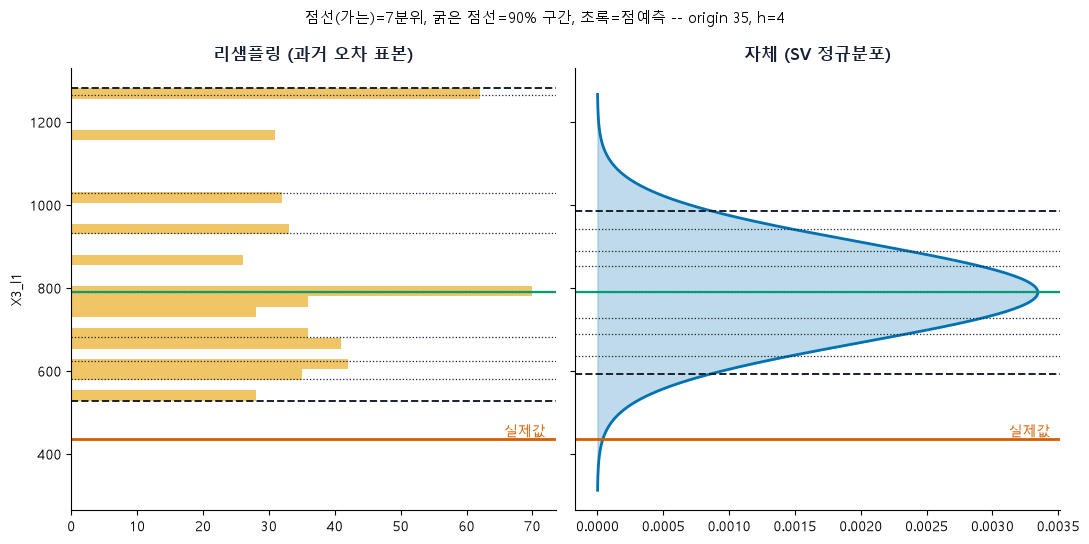

In [3]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

ex = example
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharey=True)
axes[0].hist(ex["samples"], bins=30, color="#E69F00", alpha=0.6, orientation="horizontal")
for q in ex["q_res"]:
    axes[0].axhline(q, color="#172033", linewidth=0.9, linestyle=":")
axes[0].axhline(ex["lo_r"], color="#172033", linestyle="--", linewidth=1.4)
axes[0].axhline(ex["hi_r"], color="#172033", linestyle="--", linewidth=1.4)
axes[0].set_title("리샘플링 (과거 오차 표본)", fontsize=12, fontweight="bold", color="#172033")
yy = np.linspace(ex["fc"] - 4 * ex["sig"], ex["fc"] + 4 * ex["sig"], 300)
axes[1].plot(stats.norm.pdf(yy, ex["fc"], ex["sig"]), yy, color="#0072B2", linewidth=2)
axes[1].fill_betweenx(yy, 0, stats.norm.pdf(yy, ex["fc"], ex["sig"]), color="#0072B2", alpha=0.25)
for q in ex["q_self"]:
    axes[1].axhline(q, color="#172033", linewidth=0.9, linestyle=":")
axes[1].axhline(ex["lo_n"], color="#172033", linestyle="--", linewidth=1.4)
axes[1].axhline(ex["hi_n"], color="#172033", linestyle="--", linewidth=1.4)
axes[1].set_title("자체 (SV 정규분포)", fontsize=12, fontweight="bold", color="#172033")
for ax in axes:
    ax.axhline(ex["actual"], color="#D55E00", linewidth=2)
    ax.text(ax.get_xlim()[1] * 0.98, ex["actual"], " 실제값", color="#D55E00", ha="right", va="bottom", fontsize=10)
    ax.axhline(ex["fc"], color="#009E73", linewidth=1.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[0].set_ylabel("X3_l1")
fig.suptitle("점선(가는)=7분위, 굵은 점선=90% 구간, 초록=점예측 -- origin 35, h=4", fontsize=11)
fig.tight_layout()
plt.show()


## 2. 결과 -- 22개 origin 전체 평균

22개 origin x h=1~4 = 88개를 방식별로 평균한다. 구간폭은 90% 구간의 폭을 `var_std`로 나눈 값이다. MSE는 같은 점예측을 공유하므로 같다.


In [4]:
cols = ["적중", "MSE", "CRPS(7분위)", "구간폭"]
summary = res.groupby("방식")[cols].mean().rename(columns={"적중": "커버리지(%)"}).round(3)
display(summary)
print("h별:")
display(res.groupby(["방식", "h"])[["적중", "CRPS(7분위)", "구간폭"]].mean().rename(columns={"적중": "커버리지(%)"}).round(3).unstack("방식"))
ref = pd.read_pickle("../cache/cache_93_resample_vs_self_df.pkl").groupby("방식")[cols].mean().rename(columns={"적중": "커버리지(%)"}).round(3)
print("참고: 9-3 auto_arima (q 허용) 결과")
display(ref)


,커버리지(%),MSE,CRPS(7분위),구간폭
방식,,,,
리샘플링,81.818,1.053,0.604,3.484
자체,64.773,1.053,0.589,1.795


h별:


커버리지(%)         CRPS(7분위)           구간폭       
방식    리샘플링      자체      리샘플링     자체   리샘플링     자체
h                                                
1   86.364  72.727     0.320  0.319  1.834  1.225
2   72.727  68.182     0.537  0.524  2.899  1.670
3   86.364  54.545     0.695  0.691  4.041  2.005
4   81.818  63.636     0.862  0.824  5.163  2.281

참고: 9-3 auto_arima (q 허용) 결과


,커버리지(%),MSE,CRPS(7분위),구간폭
방식,,,,
리샘플링,69.318,1.164,0.598,2.227
자체,61.364,1.164,0.621,1.705


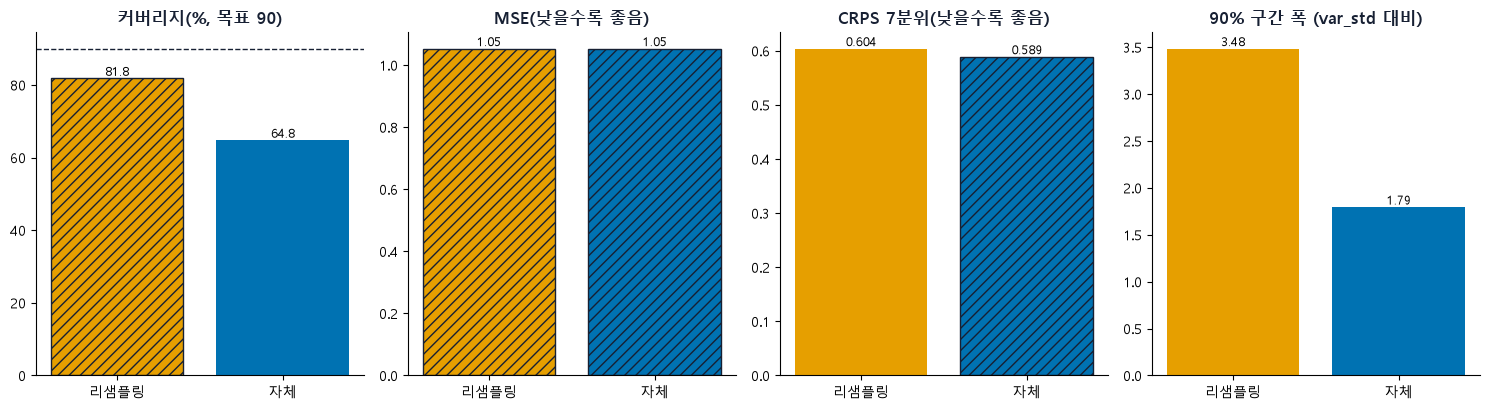

In [5]:
colr = {"리샘플링": "#E69F00", "자체": "#0072B2"}
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, (c, t) in zip(axes, [("커버리지(%)", "커버리지(%, 목표 90)"), ("MSE", "MSE(낮을수록 좋음)"), ("CRPS(7분위)", "CRPS 7분위(낮을수록 좋음)"), ("구간폭", "90% 구간 폭 (var_std 대비)")]):
    bars = ax.bar(summary.index, summary[c], color=[colr[i] for i in summary.index])
    if c != "구간폭":
        score = (summary[c] - 90).abs() if c.startswith("커버리지") else summary[c]
        for b, k in zip(bars, summary.index):
            if score[k] <= score.min() + 1e-9:
                b.set_hatch("///")
                b.set_edgecolor("#172033")
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.3g}", ha="center", va="bottom", fontsize=9)
    if c == "커버리지(%)":
        ax.axhline(90, color="#172033", linestyle="--", linewidth=1)
    ax.set_title(t, fontsize=12, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


## 3. origin별 추이

두 방식의 커버리지와 CRPS가 origin마다 어떻게 다른지 본다(origin당 h=1~4 평균, 예측 시작 분기 표기).


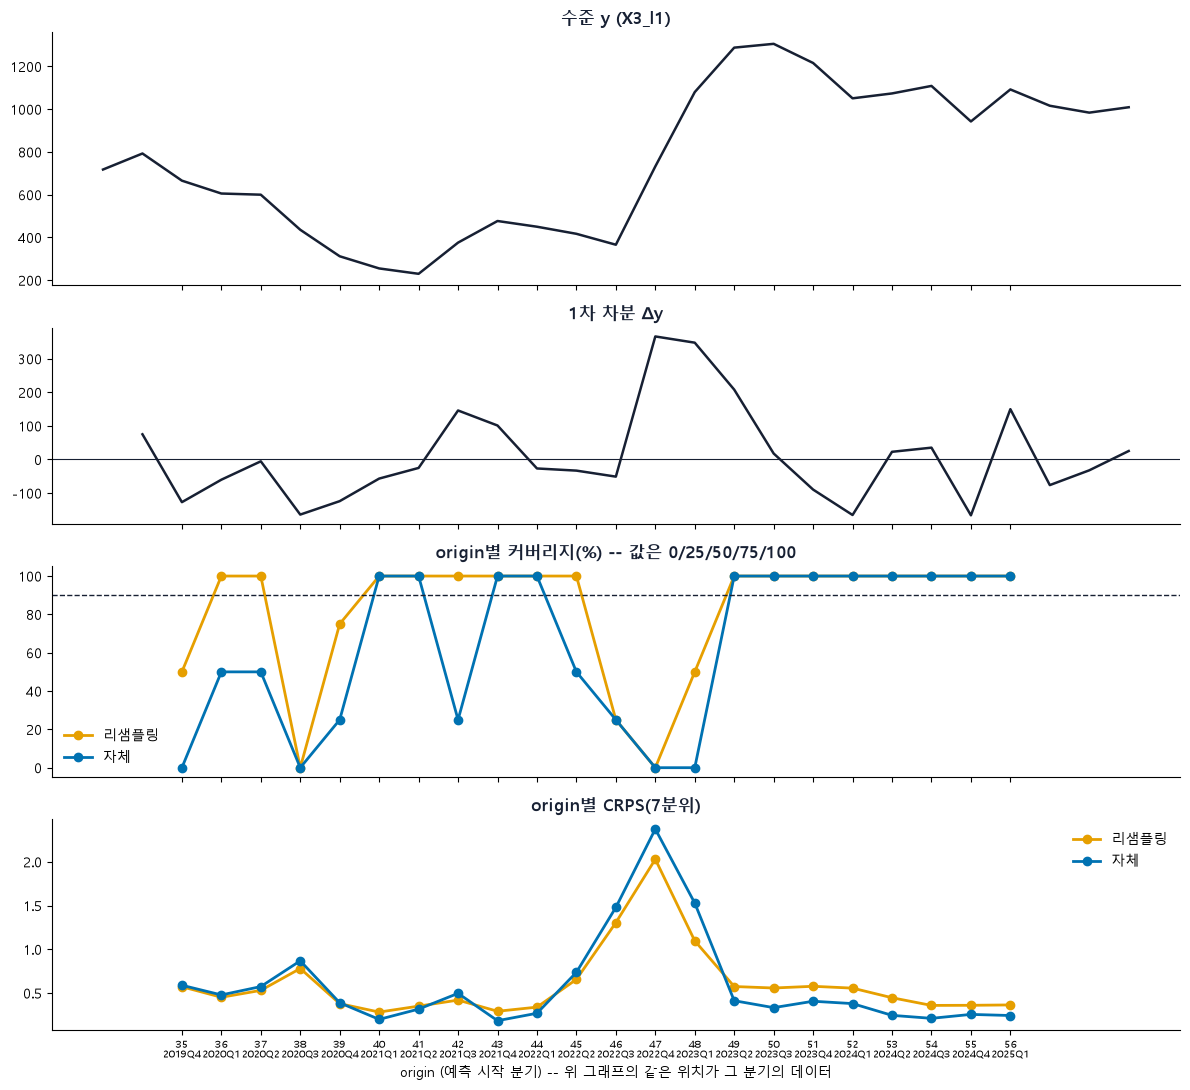

In [6]:
per = res.groupby(["방식", "origin"])[["적중", "CRPS(7분위)"]].mean()
xl = [f"{o}\n{quarters[o]}" for o in scored_origins]
t0 = scored_origins[0] - 2
tt = np.arange(t0, len(vals))
dyv = np.diff(vals)
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True, gridspec_kw={"height_ratios": [1.8, 1.4, 1.5, 1.5]})
axes[0].plot(tt, vals[t0:], color="#172033", linewidth=1.8)
axes[0].set_title("수준 y (X3_l1)", fontsize=12, fontweight="bold", color="#172033")
axes[1].plot(tt[1:], dyv[t0:], color="#172033", linewidth=1.8)
axes[1].axhline(0, color="#172033", linewidth=0.8)
axes[1].set_title("1차 차분 Δy", fontsize=12, fontweight="bold", color="#172033")
for ax, c, t in [(axes[2], "적중", "origin별 커버리지(%) -- 값은 0/25/50/75/100"), (axes[3], "CRPS(7분위)", "origin별 CRPS(7분위)")]:
    for name in ["리샘플링", "자체"]:
        ax.plot(scored_origins, per.loc[name][c].values, marker="o", color=colr[name], linewidth=2, label=name)
    ax.set_title(t, fontsize=12, fontweight="bold", color="#172033")
    ax.legend(frameon=False)
axes[2].axhline(90, color="#172033", linestyle="--", linewidth=1)
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[3].set_xticks(scored_origins)
axes[3].set_xticklabels(xl, fontsize=7)
axes[3].set_xlabel("origin (예측 시작 분기) -- 위 그래프의 같은 위치가 그 분기의 데이터")
fig.tight_layout()
plt.show()


## 4. 결론

**SV 원 스케일에서는 표준화 오차 리샘플링이 구간을 1.9배로 넓혀 커버리지를 올리지만, CRPS는 약간 나쁘고 같은 90%로 맞추면 같다.** 구간이 넓은 만큼 점수에서 이득이 없다.

| 항목 | 자체 | 리샘플링(표준화) |
|---|---|---|
| 90% 커버리지 | 64.8% | 81.8% |
| CRPS(7분위) | 0.589 | 0.604 |
| 90% 구간 폭 | 1.795 | 3.484 |
| 같은 90%로 맞춘 폭 / 구간점수 | 3.707 / 5.246 | 4.530 / 5.252 |

- 커버리지는 17%p 오르지만 CRPS는 22개 중 10개 origin에서만 리샘플링이 낮다(평균 차이 +0.014). 같은 폭으로 맞추면 구간점수가 같다(5.252 vs 5.246).
- SV σ는 실제 오차보다 작다(실제 오차 ÷ σ = 1.87). 표준화 오차 표본의 표준편차가 1.86으로 이와 거의 일치해서, 리샘플링이 σ 부족을 그대로 반영해 구간을 넓힌다. 이 점이 GARCH(과거 1.82 > 실제 1.38)와 다르다.
- σ가 h에 따라 커지는 속도(1.00→1.86)가 실제 오차(1.00→2.45)보다 느리다. h=1의 필요 배율은 1.53, h=4는 2.27이라 긴 h일수록 σ가 부족하다.
- 점예측 MSE는 1.053으로 GARCH(1.067)와 거의 같다. SV의 AR 계수가 0 근처라 점예측이 랜덤워크에 가깝다(9-5).
- 한계: 22개 origin이 겹치므로 기술적 비교이며 유의성 검정은 하지 않았다.


## 5. 두 방식의 차이 분석 (추가 연구)

위 결과에서 리샘플링과 자체 구간의 차이가 **실제로 있는지, 폭 때문인지**를 본다. 검정(부트스트랩·DM)은 쓰지 않고 다음 두 가지로 확인한다.

1. **짝지은 차이**: 같은 origin에서 두 방식의 차이(리샘플링 - 자체)를 구해, 평균이 아니라 origin마다 어떻게 나오는지(몇 개 origin에서 앞서는지, 차이가 한 구간에 몰리는지) 본다.
2. **같은 폭에서 비교**: 커버리지 차이는 구간 폭 차이와 섞여 있다. 두 가지로 폭 효과를 뺀다.
   - **구간 점수(interval score, α=0.10)**: `폭 + (2/α) x 구간을 벗어난 거리`를 `var_std`로 나눈 값이다. 넓어서 커버리지가 오른 것은 폭 항으로 벌점을 받는다. 낮을수록 좋다.
   - **90%를 맞추는 데 필요한 배율 k**: 구간을 점예측을 중심으로 k배로 늘리거나 줄인다(`점예측 + k x (경계 - 점예측)`). 88개 전체의 커버리지가 90%가 되는 최소 k와 그때의 폭을 비교한다. k가 1에 가깝고 폭이 좁을수록 구간의 모양이 잘 맞는 방식이다.


In [7]:
DF = res.copy()
ALPHA_IS = 0.10
DF["구간점수"] = ((DF["hi"] - DF["lo"]) + (2 / ALPHA_IS) * np.maximum(DF["lo"] - DF["actual"], 0)
              + (2 / ALPHA_IS) * np.maximum(DF["actual"] - DF["hi"], 0)) / var_std

po = DF.groupby(["방식", "origin"])[["CRPS(7분위)", "구간점수", "적중", "구간폭"]].mean()
dif = po.loc["리샘플링"] - po.loc["자체"]        # 리샘플링 - 자체 (origin별)
rows = []
for c, better in [("CRPS(7분위)", "neg"), ("구간점수", "neg"), ("적중", "pos")]:
    d_ = dif[c]
    n_better = int((d_ < -1e-9).sum()) if better == "neg" else int((d_ > 1e-9).sum())
    n_worse = int((d_ > 1e-9).sum()) if better == "neg" else int((d_ < -1e-9).sum())
    rows.append({"지표": c.replace("적중", "커버리지(%)"), "평균 차이": d_.mean(), "중앙값 차이": d_.median(),
                 "리샘플링이 앞선 origin": n_better, "뒤진 origin": n_worse, "같은 origin": len(d_) - n_better - n_worse})
display(pd.DataFrame(rows).set_index("지표").round(3))
print("차이 = 리샘플링 - 자체. CRPS·구간점수는 음수면 리샘플링이 낫고, 커버리지는 양수면 리샘플링이 높다. 22개 origin 기준.")

split = np.where(dif.index <= 46, "origin 35~46 (예측 시작 2022Q3 이전)", "origin 47~56 (2022Q4 이후)")
print("구간별 평균 차이 (리샘플링 - 자체):")
display(dif.groupby(split).mean().rename(columns={"적중": "커버리지(%)"}).round(3))
hdiff = (DF[DF["방식"] == "리샘플링"].groupby("h")[["CRPS(7분위)", "구간점수", "적중"]].mean()
         - DF[DF["방식"] == "자체"].groupby("h")[["CRPS(7분위)", "구간점수", "적중"]].mean())
print("h별 평균 차이 (리샘플링 - 자체):")
display(hdiff.rename(columns={"적중": "커버리지(%)"}).round(3))


,평균 차이,중앙값 차이,리샘플링이 앞선 origin,뒤진 origin,같은 origin
지표,,,,,
CRPS(7분위),0.014,0.052,10,12,0
구간점수,-1.385,1.280,9,13,0
커버리지(%),17.045,0.000,7,0,15


차이 = 리샘플링 - 자체. CRPS·구간점수는 음수면 리샘플링이 낫고, 커버리지는 양수면 리샘플링이 높다. 22개 origin 기준.
구간별 평균 차이 (리샘플링 - 자체):


,CRPS(7분위),구간점수,커버리지(%),구간폭
origin 35~46 (예측 시작 2022Q3 이전),-0.018,-1.790,27.083,1.139
origin 47~56 (2022Q4 이후),0.053,-0.898,5.000,2.350


h별 평균 차이 (리샘플링 - 자체):


,CRPS(7분위),구간점수,커버리지(%)
h,,,
1,0.001,-0.247,13.636
2,0.014,-1.267,4.545
3,0.004,-1.551,31.818
4,0.038,-2.474,18.182


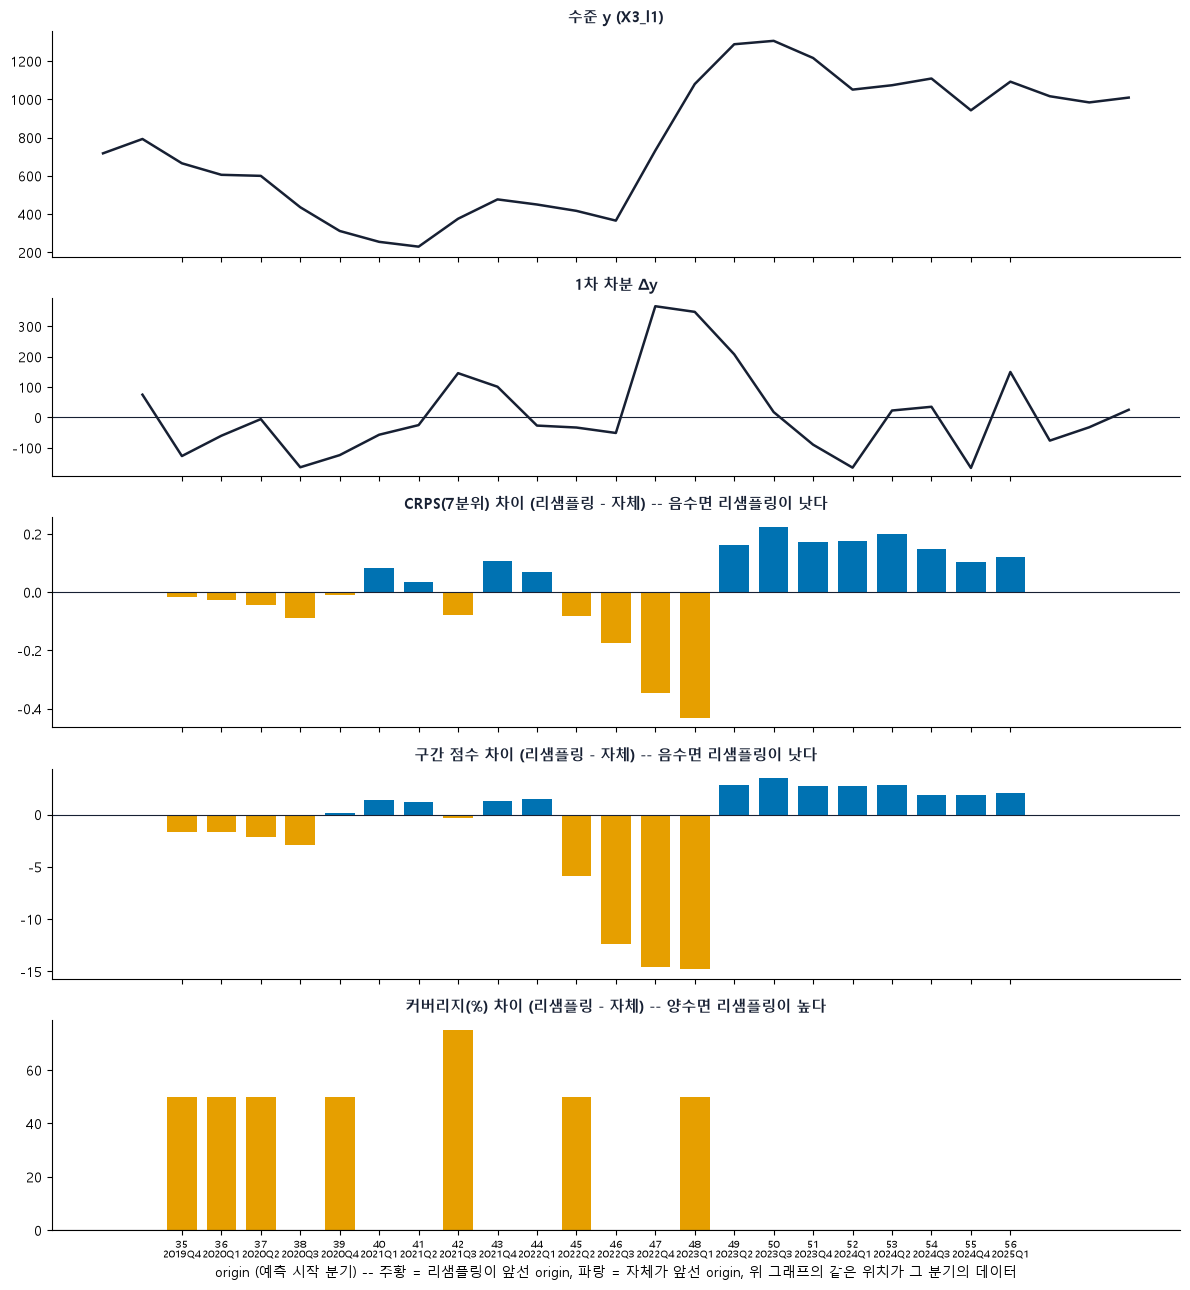

In [8]:
xl2 = [f"{o}\n{quarters[o]}" for o in scored_origins]
t0 = scored_origins[0] - 2
tt = np.arange(t0, len(vals))
dyv = np.diff(vals)
fig, axes = plt.subplots(5, 1, figsize=(12, 13), sharex=True, gridspec_kw={"height_ratios": [1.4, 1.1, 1.3, 1.3, 1.3]})
axes[0].plot(tt, vals[t0:], color="#172033", linewidth=1.8)
axes[0].set_title("수준 y (X3_l1)", fontsize=11, fontweight="bold", color="#172033")
axes[1].plot(tt[1:], dyv[t0:], color="#172033", linewidth=1.8)
axes[1].axhline(0, color="#172033", linewidth=0.8)
axes[1].set_title("1차 차분 Δy", fontsize=11, fontweight="bold", color="#172033")
for ax, c, t, good_neg in [(axes[2], "CRPS(7분위)", "CRPS(7분위) 차이 (리샘플링 - 자체) -- 음수면 리샘플링이 낫다", True),
                           (axes[3], "구간점수", "구간 점수 차이 (리샘플링 - 자체) -- 음수면 리샘플링이 낫다", True),
                           (axes[4], "적중", "커버리지(%) 차이 (리샘플링 - 자체) -- 양수면 리샘플링이 높다", False)]:
    v = dif[c].values
    good = (v < 0) if good_neg else (v > 0)
    ax.bar(scored_origins, v, color=np.where(good, "#E69F00", "#0072B2"), width=0.75)
    ax.axhline(0, color="#172033", linewidth=0.8)
    ax.set_title(t, fontsize=11, fontweight="bold", color="#172033")
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[4].set_xticks(scored_origins)
axes[4].set_xticklabels(xl2, fontsize=7)
axes[4].set_xlabel("origin (예측 시작 분기) -- 주황 = 리샘플링이 앞선 origin, 파랑 = 자체가 앞선 origin, 위 그래프의 같은 위치가 그 분기의 데이터")
fig.tight_layout()
plt.show()


### 5-1. 같은 폭에서 비교 -- 구간 점수와 90% 도달 배율


In [9]:
LOGMODE = False


def interval_at(g, k):
    fc, lo, hi, a = g["fc"].values, g["lo"].values, g["hi"].values, g["actual"].values
    if LOGMODE:
        lo_k = np.exp(np.log(fc) + k * (np.log(lo) - np.log(fc)))
        hi_k = np.exp(np.log(fc) + k * (np.log(hi) - np.log(fc)))
    else:
        lo_k, hi_k = fc + k * (lo - fc), fc + k * (hi - fc)
    cov = np.mean((a >= lo_k) & (a <= hi_k)) * 100
    width = np.mean(hi_k - lo_k) / var_std
    iscore = np.mean((hi_k - lo_k) + (2 / ALPHA_IS) * np.maximum(lo_k - a, 0) + (2 / ALPHA_IS) * np.maximum(a - hi_k, 0)) / var_std
    return cov, width, iscore


rows = []
for name in ["리샘플링", "자체"]:
    g = DF[DF["방식"] == name]
    cov1, w1, is1 = interval_at(g, 1.0)
    ks = np.linspace(0.2, 8, 1561)
    k90 = next((k for k in ks if interval_at(g, k)[0] >= 90), np.nan)
    cov90, w90, is90 = interval_at(g, k90) if not np.isnan(k90) else (np.nan, np.nan, np.nan)
    rows.append({"방식": name, "원래 커버리지(%)": cov1, "원래 폭": w1, "원래 구간점수": is1,
                 "90% 도달 배율 k": k90, "그때의 폭": w90, "그때의 구간점수": is90})
display(pd.DataFrame(rows).set_index("방식").round(3))
print("k < 1이면 구간을 줄여도 90%에 도달(원래 구간이 넓음), k > 1이면 늘려야 90%에 도달한다. 폭과 구간점수는 var_std로 나눈 값이다.")


,원래 커버리지(%),원래 폭,원래 구간점수,90% 도달 배율 k,그때의 폭,그때의 구간점수
방식,,,,,,
리샘플링,81.818,3.484,5.192,1.300,4.530,5.252
자체,64.773,1.795,6.576,2.065,3.707,5.246


k < 1이면 구간을 줄여도 90%에 도달(원래 구간이 넓음), k > 1이면 늘려야 90%에 도달한다. 폭과 구간점수는 var_std로 나눈 값이다.


### 5-2. 소결

- 기본 비교는 커버리지가 리샘플링이 높지만(81.8 vs 64.8) 폭이 1.9배 넓고(3.484 vs 1.795), CRPS는 자체가 약간 낫다(0.589 vs 0.604).
- 같은 90%로 맞추면 구간점수가 같다(5.252 vs 5.246). 구간 모양에서 어느 쪽이 낫다는 증거는 없다.
- h별 CRPS 차이는 +0.001, +0.014, +0.004, +0.038로 h=4에서 자체가 더 낫다. 앞 구간(origin 35~46)은 리샘플링이 약간 낫고(-0.018), 뒤 구간(47~56)은 자체가 낫다(+0.053).


## 6. 리샘플링 구간이 넓은 이유와 h별 특징

리샘플링의 구간 폭이 자체 구간보다 넓었다. 이유를 다음 가설로 확인하고, h(예측 단계)에 따라 오차와 σ가 어떻게 다른지 본다. 구간을 늘려 90%를 맞추는 배율 k_h는 평가 방법이 아니라 **진단용**으로만 보여 준다(보정한 구간을 평가 대상으로 쓰지 않는다).

- **가설 1**: 모델 σ는 훈련 데이터의 오차에서 추정되는데, 리샘플링은 **실제 out-of-sample 예측오차**를 모아서 만든다. 후자가 크면 리샘플링 구간이 넓다. 오차 표본의 표준편차와 모델 σ의 비율로 확인한다.
- **가설 2**: 큰 충격(급등 시기)의 오차가 오차 표본에 남아 이후 구간을 계속 넓힌다. 오차 표본의 표준편차가 origin에 따라 어떻게 변하는지 본다.
- **h별 확인**: 모델 σ가 h에 따라 커지는 정도가 실제 오차가 커지는 정도와 맞는가.

단위: 오차와 σ는 원 단위이다.


In [10]:
DF = res.copy()
r = DF[DF["방식"] == "리샘플링"].set_index(["origin", "h"])
s = DF[DF["방식"] == "자체"].set_index(["origin", "h"])
sigma = s["sigma_model"]                       # 모델 σ (원 단위)
err = r['actual'] - r['fc']                                    # 점예측 오차 (원 단위)
z = err / sigma
dd = pd.DataFrame({"오차": err, "σ": sigma, "z": z, "오차표본std": r["pool_std"], "오차표본최대": r["pool_absmax"],
                   "폭비율": (r['hi'] - r['lo']) / (s['hi'] - s['lo']), "표본n": r["pool_n"]})
dd["표본std/σ"] = dd["오차표본std"] / dd["σ"]

print("전체 평균 -- 오차 표본 표준편차 ÷ 모델 σ:", round(dd["표본std/σ"].mean(), 3), " / 구간 폭 비율(리샘플링÷자체):", round(dd["폭비율"].mean(), 3))
print("실제 오차(88개)의 표준편차 ÷ 모델 σ 평균:", round(dd["오차"].std() / dd["σ"].mean(), 3))


전체 평균 -- 오차 표본 표준편차 ÷ 모델 σ: 1.863  / 구간 폭 비율(리샘플링÷자체): 1.844
실제 오차(88개)의 표준편차 ÷ 모델 σ 평균: 1.873


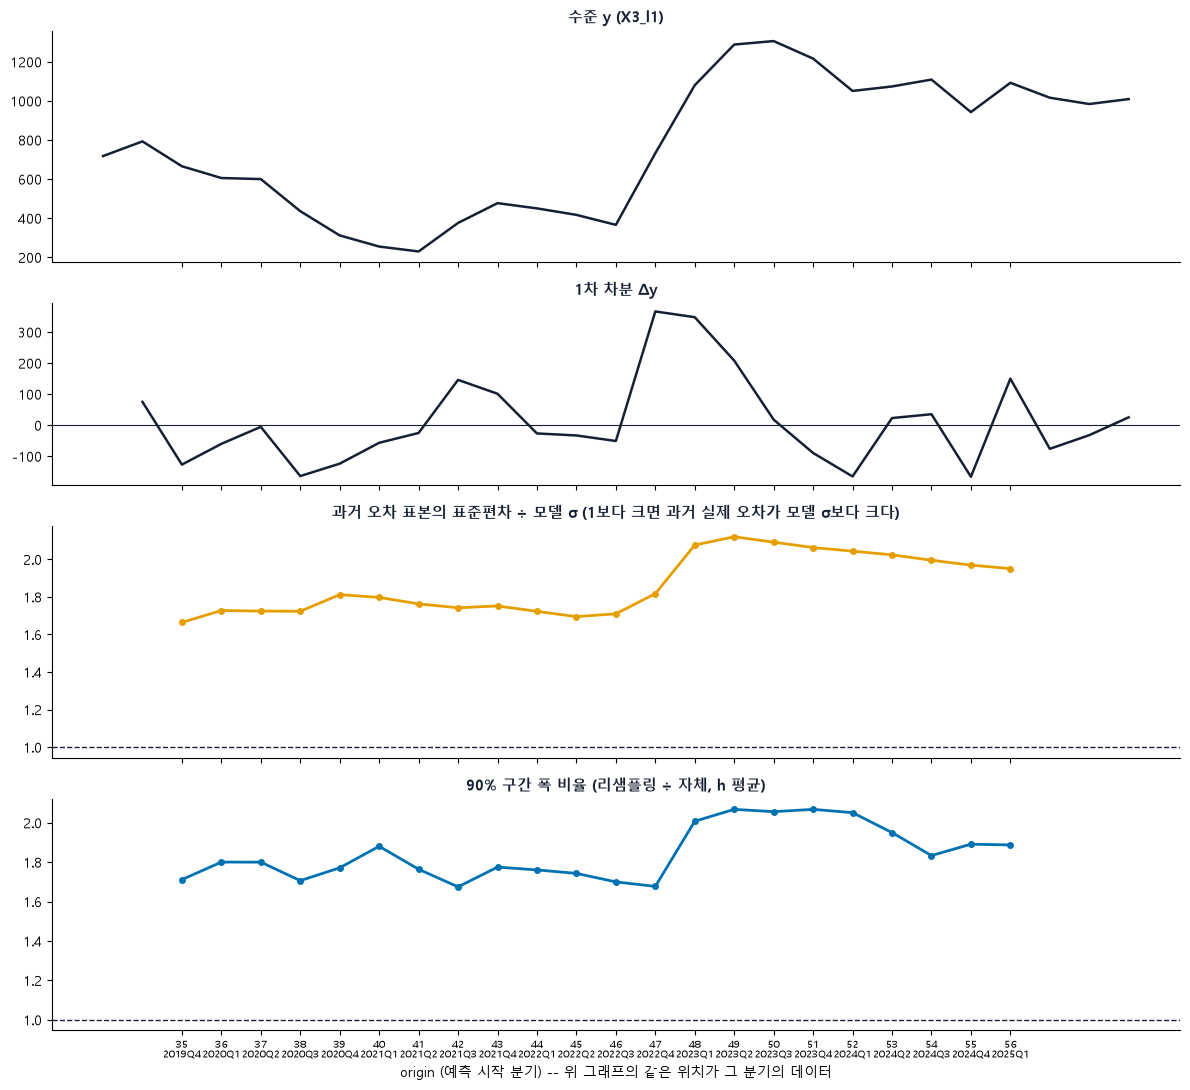

구간별 평균:


,표본std/σ,폭비율
origin 35~46,1.736,1.757
origin 47~56,2.015,1.949


In [11]:
per_o = dd.groupby("origin")[["표본std/σ", "폭비율"]].mean()
xl3 = [f"{o}\n{quarters[o]}" for o in scored_origins]
t0 = scored_origins[0] - 2
tt = np.arange(t0, len(vals))
dyv = np.diff(vals)
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True, gridspec_kw={"height_ratios": [1.4, 1.1, 1.4, 1.4]})
axes[0].plot(tt, vals[t0:], color="#172033", linewidth=1.8)
axes[0].set_title("수준 y (X3_l1)", fontsize=11, fontweight="bold", color="#172033")
axes[1].plot(tt[1:], dyv[t0:], color="#172033", linewidth=1.8)
axes[1].axhline(0, color="#172033", linewidth=0.8)
axes[1].set_title("1차 차분 Δy", fontsize=11, fontweight="bold", color="#172033")
axes[2].plot(scored_origins, per_o["표본std/σ"].values, marker="o", ms=4, color="#E69F00", linewidth=2)
axes[2].axhline(1, color="#172033", linestyle="--", linewidth=1)
axes[2].set_title("과거 오차 표본의 표준편차 ÷ 모델 σ (1보다 크면 과거 실제 오차가 모델 σ보다 크다)", fontsize=11, fontweight="bold", color="#172033")
axes[3].plot(scored_origins, per_o["폭비율"].values, marker="o", ms=4, color="#0072B2", linewidth=2)
axes[3].axhline(1, color="#172033", linestyle="--", linewidth=1)
axes[3].set_title("90% 구간 폭 비율 (리샘플링 ÷ 자체, h 평균)", fontsize=11, fontweight="bold", color="#172033")
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[3].set_xticks(scored_origins)
axes[3].set_xticklabels(xl3, fontsize=7)
axes[3].set_xlabel("origin (예측 시작 분기) -- 위 그래프의 같은 위치가 그 분기의 데이터")
fig.tight_layout()
plt.show()

print("구간별 평균:")
split = np.where(per_o.index <= 46, "origin 35~46", "origin 47~56")
display(per_o.groupby(split).mean().round(3))


### 6-1. h별 특징 -- 오차와 σ가 h에 따라 어떻게 커지나

h=1~4마다 실제 오차의 표준편차, 모델 σ의 평균, 둘의 비율, h=1 대비 증가율을 본다. `k_h`는 그 h에서 90%를 맞추는 데 필요한 배율(`|z|`의 90분위 ÷ 1.645)로 **진단용**이다.


,실제 오차 표준편차,모델 σ 평균,오차 표본 표준편차 평균,리샘플링÷자체 폭,k_h (진단),오차÷σ,오차 증가율(h=1=1),σ 증가율(h=1=1)
h,,,,,,,,
1,155.982,105.270,151.008,1.470,1.535,1.482,1.000,1.000
2,256.218,143.497,269.982,1.712,1.981,1.786,1.643,1.363
3,330.038,172.224,360.914,1.985,2.036,1.916,2.116,1.636
4,381.380,195.974,431.672,2.210,2.272,1.946,2.445,1.862


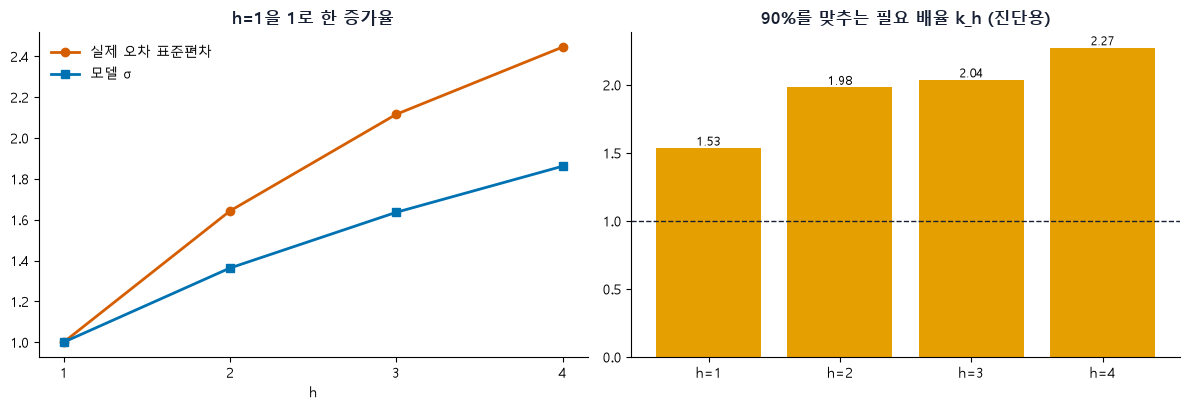

In [12]:
hg = dd.groupby("h")
htab = pd.DataFrame({
    "실제 오차 표준편차": hg["오차"].std(),
    "모델 σ 평균": hg["σ"].mean(),
    "오차 표본 표준편차 평균": hg["오차표본std"].mean(),
    "리샘플링÷자체 폭": hg["폭비율"].mean(),
    "k_h (진단)": hg["z"].apply(lambda x: np.quantile(np.abs(x), 0.9) / Z),
})
htab["오차÷σ"] = htab["실제 오차 표준편차"] / htab["모델 σ 평균"]
htab["오차 증가율(h=1=1)"] = htab["실제 오차 표준편차"] / htab["실제 오차 표준편차"].iloc[0]
htab["σ 증가율(h=1=1)"] = htab["모델 σ 평균"] / htab["모델 σ 평균"].iloc[0]
display(htab.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
hs = htab.index.values
axes[0].plot(hs, htab["오차 증가율(h=1=1)"], marker="o", color="#D55E00", linewidth=2, label="실제 오차 표준편차")
axes[0].plot(hs, htab["σ 증가율(h=1=1)"], marker="s", color="#0072B2", linewidth=2, label="모델 σ")
axes[0].set_xticks(hs)
axes[0].set_title("h=1을 1로 한 증가율", fontsize=12, fontweight="bold", color="#172033")
axes[0].set_xlabel("h")
axes[0].legend(frameon=False)
bars = axes[1].bar([f"h={h}" for h in hs], htab["k_h (진단)"], color="#E69F00")
for b in bars:
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.2f}", ha="center", va="bottom", fontsize=9)
axes[1].axhline(1, color="#172033", linestyle="--", linewidth=1)
axes[1].set_title("90%를 맞추는 필요 배율 k_h (진단용)", fontsize=12, fontweight="bold", color="#172033")
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


### 6-2. 소결

- 과거 표준화 오차의 표준편차(오차 표본 std ÷ σ)가 1.86이고 구간 폭 비율이 1.84다. 리샘플링이 넓은 것은 모델 σ가 실제 오차보다 작아서다.
- 평가 구간의 실제 오차 std ÷ σ도 1.87로 비슷하다. auto_arima(약 2.07)와 같은 방향이고 GARCH(1.38)보다 심하다.
- h=1 대비 증가율은 오차 1.00→2.45, σ 1.00→1.86이다. SV의 σ 증가가 느린 것은 로그변동성이 평균으로 돌아오는 구조(phi<1)라서다. 리샘플링 폭 비율은 h=1의 1.47에서 h=4의 2.21로 커진다.
